<a href="https://colab.research.google.com/github/kevinx0619/clock-test/blob/master/notebooks/python_inference_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import IPython.display as ipd

from magenta_rt import MagentaRT2Jax


In [5]:
!pip install magenta-rt
!mrt models init

Initializing model resources from HuggingFace → /root/Documents/Magenta/magenta-rt-v2

📦 Downloading resources/musiccoca …

📦 Downloading resources/spectrostream …

✓ Init complete.


## Jax API

In [8]:
mrt = MagentaRT2Jax(size="mrt2_small")
embedding = mrt.embed_style("disco funk")

In [7]:
!mrt checkpoints download mrt2_small


📦 Downloading checkpoint mrt2_small.safetensors from HuggingFace → /root/Documents/Magenta/magenta-rt-v2/checkpoints/mrt2_small.safetensors …

checkpoints/mrt2_small.safetensors: downloading bytes:  17% 191M/1.13G [00:01<00:04, 206MB/s, 14.4MB/s  ]
checkpoints/mrt2_small.safetensors: downloading bytes:  26% 291M/1.13G [00:02<00:03, 269MB/s, 23.3MB/s  ]
checkpoints/mrt2_small.safetensors: downloading bytes:  72% 807M/1.13G [00:03<00:01, 284MB/s, 65.5MB/s  ]
checkpoints/mrt2_small.safetensors: downloading bytes:  91% 1.03G/1.13G [00:05<00:01, 99.5MB/s, 74.0MB/s  ]
checkpoints/mrt2_small.safetensors: downloading bytes:  93% 1.05G/1.13G [00:06<00:00, 100MB/s, 74.0MB/s  ] 
checkpoints/mrt2_small.safetensors: reconstructing file:  87% 983M/1.13G [00:10<00:01, 94.3MB/s, 54.2MB/s  ]
checkpoints/mrt2_small.safetensors: reconstructing file:  90% 1.01G/1.13G [00:10<00:01, 97.8MB/s, 62.0MB/s  ]
checkpoints/mrt2_small.safetensors: reconstructing file:  94% 1.06G/1.13G [00:10<00:00, 104MB/s, 64.3MB

In [13]:
wav, state = mrt.generate(conditioning={"mulan_tokens_25hz": embedding}, frames=250, state=None)

In [10]:
import inspect
print(inspect.signature(mrt.generate))

(conditioning: dict[str, list[int] | numpy.ndarray] | None = None, cfg_scales: dict[str, float] | None = None, temperature: float | None = None, top_k: int | None = None, frames: int = 25, state: jaxtyping.PyTree[jaxtyping.Shaped[ArrayT, '...']] | None = None) -> tuple[magenta_rt.audio.Waveform, jaxtyping.PyTree[jaxtyping.Shaped[ArrayT, '...']]]


In [14]:
ipd.display(ipd.Audio(wav.samples.T, rate=48000))

In [15]:
import numpy as np

# 前 10 秒：風格 A
emb1 = mrt.embed_style("chill jazz piano")
wav1, state = mrt.generate(conditioning={"mulan_tokens_25hz": emb1}, frames=250, state=None)

# 後 10 秒：把剛剛的 state 傳進去，換成風格 B
emb2 = mrt.embed_style("energetic electronic dance music")
wav2, state = mrt.generate(conditioning={"mulan_tokens_25hz": emb2}, frames=250, state=state)

# 把兩段音訊接在一起播放
combined = np.concatenate([wav1.samples, wav2.samples], axis=0)
ipd.display(ipd.Audio(combined.T, rate=48000))

In [19]:
import numpy as np

# 1. 探索地圖（6 秒）
e1 = mrt.embed_style("calm ambient forest flute and soft harp")
w1, st = mrt.generate(conditioning={"mulan_tokens_25hz": e1}, frames=150, state=None)

# 2. 進入警戒（6 秒）
e2 = mrt.embed_style("tense suspenseful strings with deep pulsing bass")
w2, st = mrt.generate(conditioning={"mulan_tokens_25hz": e2}, frames=150, state=st)

# 3. Boss 戰爆發（8 秒）
e3 = mrt.embed_style("epic orchestral boss battle with heavy drums and brass")
w3, st = mrt.generate(conditioning={"mulan_tokens_25hz": e3}, frames=200, state=st)

game_bgm = np.concatenate([w1.samples, w2.samples, w3.samples], axis=0)
ipd.display(ipd.Audio(game_bgm.T, rate=48000))

In [20]:
import numpy as np

# 1. 只有獨奏鋼琴
e1 = mrt.embed_style("solo acoustic piano, simple melody")
w1, st = mrt.generate(conditioning={"mulan_tokens_25hz": e1}, frames=150, state=None)

# 2. 加入爵士鼓跟貝斯
e2 = mrt.embed_style("jazz piano trio with walking bass and light drums")
w2, st = mrt.generate(conditioning={"mulan_tokens_25hz": e2}, frames=150, state=st)

# 3. 整個交響樂團進來大爆發
e3 = mrt.embed_style("grand orchestral jazz big band with brass and strings")
w3, st = mrt.generate(conditioning={"mulan_tokens_25hz": e3}, frames=150, state=st)

buildup = np.concatenate([w1.samples, w2.samples, w3.samples], axis=0)
ipd.display(ipd.Audio(buildup.T, rate=48000))

In [26]:
emb = mrt.embed_style("upbeat pop synth melody")

# 極度保守
w_cold, _ = mrt.generate(conditioning={"mulan_tokens_25hz": emb}, temperature=0.3, frames=300, state=None)
# 極度狂野
w_hot, _ = mrt.generate(conditioning={"mulan_tokens_25hz": emb}, temperature=10.0, frames=300, state=None)

print("Temperature = 0.3 (保守/重複):")
ipd.display(ipd.Audio(w_cold.samples.T, rate=48000))
print("Temperature = 10.0 (狂野/崩壞):")
ipd.display(ipd.Audio(w_hot.samples.T, rate=48000))

Temperature = 0.3 (保守/重複):


Temperature = 10.0 (狂野/崩壞):


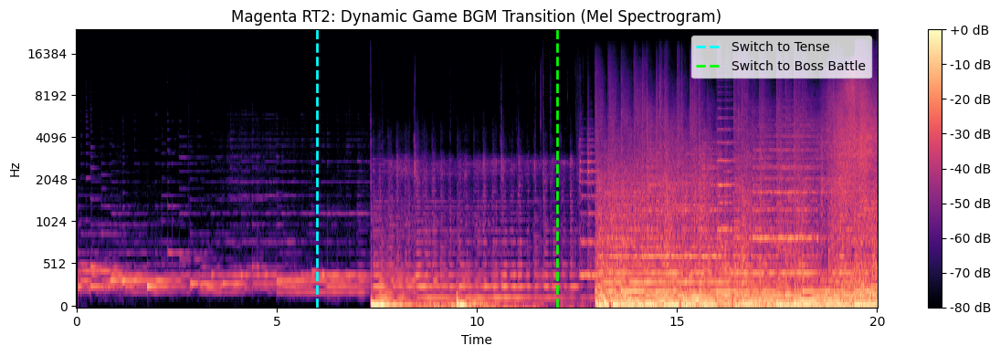

In [27]:
import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np

# 把立體聲轉成單聲道來畫圖
mono_audio = game_bgm.mean(axis=1)

# 計算梅爾頻譜
S = librosa.feature.melspectrogram(y=mono_audio, sr=48000, n_mels=128)
S_dB = librosa.power_to_db(S, ref=np.max)

plt.figure(figsize=(12, 4))
librosa.display.specshow(S_dB, sr=48000, x_axis='time', y_axis='mel', cmap='magma')
plt.colorbar(format='%+2.0f dB')

# 標出風格切換的時間點（第 6 秒、第 12 秒）
plt.axvline(x=6.0, color='cyan', linestyle='--', linewidth=2, label='Switch to Tense')
plt.axvline(x=12.0, color='lime', linestyle='--', linewidth=2, label='Switch to Boss Battle')

plt.title('Magenta RT2: Dynamic Game BGM Transition (Mel Spectrogram)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()